# Experiment 2: Data Cleaning and Transformation

In [1]:
import io
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
raw_csv = '''Order_ID,Order_Date,Ship_Date,Customer_Name,Category_SubCategory,Unit_Price,Unit_Cost,Quantity,Discount_Pct,Shipping_Cost,Payment_Mode
ORD-101,2025-01-05,2025/01/08,  Aarav Sharma ,Technology | Laptops,"$1,050.00",$700.00,2,10%,25.50,upi
ORD-102,2025-01-10,2025/01/12,Diya Nair,Furniture | Chairs,$320.00,$190.00,4,,30.00,Credit Card
ORD-102,2025-01-10,2025/01/12,Diya Nair,Furniture | Chairs,$320.00,$190.00,4,,30.00,Credit Card
ORD-103,2025-01-15,2025/01/19, Kabir Malhotra,Office Supplies | Binders,$45.50,$20.00,10,5%,,UPI
ORD-104,2025-02-01,2025/02/03,Elena Brown,Technology | Accessories,$120.00,$55.00,3,0%,15.00,digital wallet
ORD-105,2025-02-14,2025/02/20,Noah Verma ,Furniture | Tables,"$680.00",$420.00,2,15%,40.00,Bank Transfer
ORD-106,2025-02-20,2025/02/23,Mia Miller,Office Supplies | Paper,$25.00,$10.00,8,0%,12.00,Credit Card'''
df = pd.read_csv(io.StringIO(raw_csv))
print("Raw Shape:", df.shape)
print(df)

Raw Shape: (7, 11)
  Order_ID  Order_Date   Ship_Date    Customer_Name  \
0  ORD-101  2025-01-05  2025/01/08    Aarav Sharma    
1  ORD-102  2025-01-10  2025/01/12        Diya Nair   
2  ORD-102  2025-01-10  2025/01/12        Diya Nair   
3  ORD-103  2025-01-15  2025/01/19   Kabir Malhotra   
4  ORD-104  2025-02-01  2025/02/03      Elena Brown   
5  ORD-105  2025-02-14  2025/02/20      Noah Verma    
6  ORD-106  2025-02-20  2025/02/23       Mia Miller   

        Category_SubCategory Unit_Price Unit_Cost  Quantity Discount_Pct  \
0       Technology | Laptops  $1,050.00   $700.00         2          10%   
1         Furniture | Chairs    $320.00   $190.00         4          NaN   
2         Furniture | Chairs    $320.00   $190.00         4          NaN   
3  Office Supplies | Binders     $45.50    $20.00        10           5%   
4   Technology | Accessories    $120.00    $55.00         3           0%   
5         Furniture | Tables    $680.00   $420.00         2          15%   
6    Off

In [3]:
df = df.drop_duplicates().copy()
df['Customer_Name'] = df['Customer_Name'].str.strip()
df['Payment_Mode'] = df['Payment_Mode'].str.strip().str.title()
df['Payment_Mode'] = df['Payment_Mode'].replace({'Upi': 'UPI'})

df['Unit_Price'] = df['Unit_Price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['Unit_Cost'] = df['Unit_Cost'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
df['Discount_Pct'] = df['Discount_Pct'].fillna('0%').str.replace('%', '', regex=False).astype(float) / 100.0
df['Shipping_Cost'] = df['Shipping_Cost'].fillna(df['Shipping_Cost'].median())

split_cat = df['Category_SubCategory'].str.split('|', expand=True)
df['Category'] = split_cat[0].str.strip()
df['Sub_Category'] = split_cat[1].str.strip()

df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'])
df['Days_to_Ship'] = (df['Ship_Date'] - df['Order_Date']).dt.days

In [4]:
df['Net_Revenue'] = df['Unit_Price'] * df['Quantity'] * (1 - df['Discount_Pct'])
df['Profit'] = df['Net_Revenue'] - (df['Unit_Cost'] * df['Quantity']) - df['Shipping_Cost']
print("Cleaned Shape:", df.shape)
print(df[['Order_ID', 'Customer_Name', 'Category', 'Sub_Category', 'Payment_Mode', 'Days_to_Ship', 'Net_Revenue', 'Profit']])

Cleaned Shape: (6, 16)
  Order_ID   Customer_Name         Category Sub_Category    Payment_Mode  \
0  ORD-101    Aarav Sharma       Technology      Laptops             UPI   
1  ORD-102       Diya Nair        Furniture       Chairs     Credit Card   
3  ORD-103  Kabir Malhotra  Office Supplies      Binders             UPI   
4  ORD-104     Elena Brown       Technology  Accessories  Digital Wallet   
5  ORD-105      Noah Verma        Furniture       Tables   Bank Transfer   
6  ORD-106      Mia Miller  Office Supplies        Paper     Credit Card   

   Days_to_Ship  Net_Revenue  Profit  
0             3      1890.00  464.50  
1             2      1280.00  490.00  
3             4       432.25  206.75  
4             2       360.00  180.00  
5             6      1156.00  276.00  
6             3       200.00  108.00  


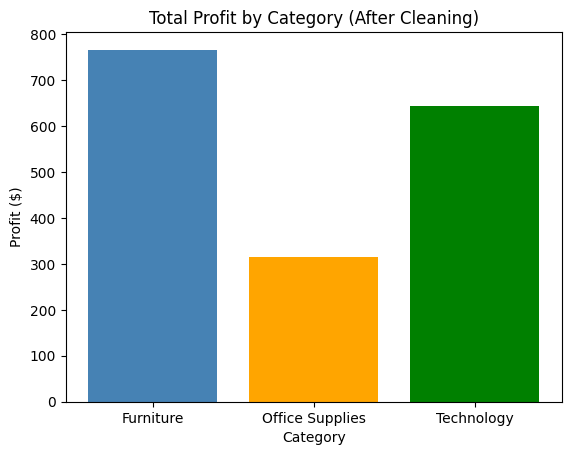

In [5]:
cat_profit = df.groupby('Category')['Profit'].sum()
plt.bar(cat_profit.index, cat_profit.values, color=['steelblue', 'orange', 'green'])
plt.title('Total Profit by Category (After Cleaning)')
plt.xlabel('Category')
plt.ylabel('Profit ($)')
plt.show()